# Heston: Four-Method Comparison on New Options

This notebook draws fresh option/model combinations that are independent of the FFT training dataset, then prices each European call with all four methods: full-truncation Monte Carlo, Carr-Madan FFT, the trained NN, and the trained GPR. The requested plot uses option index on the x-axis and predicted option price on the y-axis, with a distinct color for each method.

FFT is the numerical reference for error metrics. MC error is stochastic, so the output table includes its standard error. This notebook requires the trained artifacts from `06_heston_dataset_ml.ipynb`.

In [1]:
from pathlib import Path
import sys
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from heston_pricing import (FEATURE_NAMES, SPOT, feature_matrix, sample_fresh_options,
                            heston_fft_calls, heston_mc_call)

DATA_DIR, MODEL_DIR = ROOT / "data", ROOT / "models"
FFT_N, FFT_ETA, FFT_ALPHA = 4096, 0.25, 1.25
N_NEW = 100
MC_PATHS, MC_STEPS = 20_000, 1_000
DEVICE = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
plt.style.use("seaborn-v0_8-whitegrid")

## 1. Load the trained NN and GPR

The NN was trained on the complete FFT training split. The exact GPR was trained on the configured 5,000-row subset with a quadratic trend and squared-exponential covariance.

In [2]:
fnn_pre = joblib.load(MODEL_DIR / "heston_fnn_preprocessing.joblib")
gpr_payload = joblib.load(MODEL_DIR / "heston_gpr.joblib")
if fnn_pre["feature_names"] != FEATURE_NAMES or gpr_payload["feature_names"] != FEATURE_NAMES:
    raise ValueError("Saved model features do not match the Heston comparison schema")

class HestonMLP(nn.Module):
    def __init__(self, n_features=len(FEATURE_NAMES)):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 1),
        )
    def forward(self, x):
        return self.net(x)

fnn = HestonMLP().to(DEVICE)
fnn.load_state_dict(torch.load(MODEL_DIR / "heston_fnn.pt", map_location=DEVICE, weights_only=True))
fnn.eval()

def tensor(a):
    return torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32))

def predict_fnn(X):
    Xs = fnn_pre["scaler_X"].transform(X)
    with torch.no_grad():
        ys = fnn(tensor(Xs).to(DEVICE)).cpu().numpy()
    return fnn_pre["scaler_y"].inverse_transform(ys).ravel()

def predict_gpr(X):
    Xs = gpr_payload["scaler_X"].transform(X)
    trend = gpr_payload["trend"].predict(gpr_payload["polynomial"].transform(Xs))
    resid = gpr_payload["gp"].predict(Xs)
    return gpr_payload["scaler_y"].inverse_transform((trend + resid).reshape(-1, 1)).ravel()

print(f"Models loaded on {DEVICE}; NN trained on all training rows, GPR on its exact subset.")

Models loaded on mps; NN trained on all training rows, GPR on its exact subset.


## 2. Price fresh options with all four methods

Fresh test inputs use the paper's narrower Heston test ranges and a new random seed. Each is priced independently by MC and FFT; NN and GPR predictions are batched. The plot below compares prices on exactly the same option rows.

In [3]:
options = sample_fresh_options(N_NEW, seed=2027 + 10_000)
X_new = feature_matrix(options)

def run_fft_batch():
    return np.array([heston_fft_calls(p, [p["K"]], n=FFT_N, eta=FFT_ETA,
                                      alpha=FFT_ALPHA)[0] for p in options])

fft_prices = run_fft_batch()
fft_samples = []
for _ in range(5):
    start = time.perf_counter(); run_fft_batch(); fft_samples.append(time.perf_counter() - start)
fft_seconds = float(np.median(fft_samples))

def run_mc_batch(seed_offset):
    prices, errors = [], []
    for i, option in enumerate(options):
        estimate, se = heston_mc_call(option, n_paths=MC_PATHS, n_steps=MC_STEPS,
                                      seed=2027 + 20_000 + seed_offset + i)
        prices.append(estimate); errors.append(se)
    return np.asarray(prices), np.asarray(errors)

mc_prices, mc_ses = run_mc_batch(0)
mc_samples = []
for repeat in range(3):
    start = time.perf_counter(); run_mc_batch((repeat + 1) * 1_000)
    mc_samples.append(time.perf_counter() - start)
mc_seconds = float(np.median(mc_samples))

fnn_prices = predict_fnn(X_new)
def sync_device():
    if DEVICE.type == "mps":
        torch.mps.synchronize()
    elif DEVICE.type == "cuda":
        torch.cuda.synchronize()
sync_device()
for _ in range(5):
    predict_fnn(X_new); sync_device()
fnn_samples = []
for _ in range(15):
    sync_device(); start = time.perf_counter(); predict_fnn(X_new); sync_device()
    fnn_samples.append(time.perf_counter() - start)
fnn_seconds = float(np.median(fnn_samples))

gpr_prices = predict_gpr(X_new)
for _ in range(5):
    predict_gpr(X_new)
gpr_samples = []
for _ in range(15):
    start = time.perf_counter(); predict_gpr(X_new)
    gpr_samples.append(time.perf_counter() - start)
gpr_seconds = float(np.median(gpr_samples))

comparison = pd.DataFrame({
    "data_point": np.arange(1, N_NEW + 1),
    "forward_moneyness": [p["forward_moneyness"] for p in options],
    "FFT": fft_prices, "MC": mc_prices, "MC_standard_error": mc_ses,
    "NN": fnn_prices, "GPR": gpr_prices,
})
comparison.to_csv(DATA_DIR / "heston_four_method_new_options.csv", index=False)
display(comparison.head(10).style.format({k: "{:.5f}" for k in comparison.columns
                                          if k != "data_point"}))

,data_point,forward_moneyness,FFT,MC,MC_standard_error,NN,GPR
0,1,1.18343,1.22312,1.23600,0.02537,1.16959,1.21128
1,2,0.79826,21.86373,21.86656,0.06312,21.83299,21.86732
2,3,0.57517,42.48745,42.50824,0.08444,42.51690,42.48759
3,4,0.76155,24.79361,24.91841,0.05876,24.72850,24.79156
4,5,0.51668,46.60672,46.66183,0.08898,46.60563,46.60648
5,6,0.62676,35.94349,35.95326,0.07177,35.96317,35.94271
6,7,0.86330,16.49934,16.51190,0.05974,16.41535,16.49229
7,8,1.25745,0.33005,0.32662,0.01508,0.35877,0.32474
8,9,1.24445,1.59634,1.65225,0.03701,1.57796,1.59091
9,10,0.87760,16.36901,16.39503,0.05930,16.38029,16.36607


## 3. Requested four-color price plot

The x-axis is the index of each new option data point. The y-axis is the predicted European call price. Each method uses its own color and all four series use the same option ordering. Markers are nudged slightly left or right within each data point only to make overlapping predictions visible; the tick labels remain the original option indices.

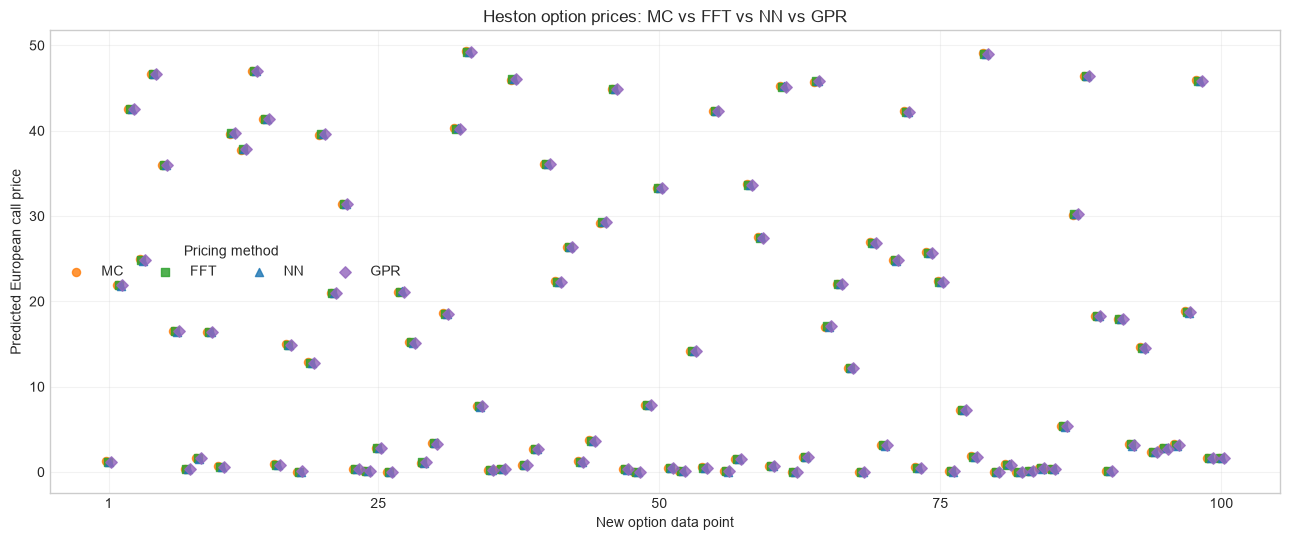

In [4]:
fig, ax = plt.subplots(figsize=(13, 5.5))
styles = {
    "MC": {"color": "tab:orange", "marker": "o"},
    "FFT": {"color": "tab:green", "marker": "s"},
    "NN": {"color": "tab:blue", "marker": "^"},
    "GPR": {"color": "tab:purple", "marker": "D"},
}
offsets = {"MC": -0.24, "FFT": -0.08, "NN": 0.08, "GPR": 0.24}
for method, style in styles.items():
    ax.scatter(comparison.data_point + offsets[method], comparison[method], s=34, alpha=0.82,
               label=method, **style)
ax.set_xticks([1, 25, 50, 75, 100])
ax.set_xlabel("New option data point")
ax.set_ylabel("Predicted European call price")
ax.set_title("Heston option prices: MC vs FFT vs NN vs GPR")
ax.legend(title="Pricing method", ncols=4)
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(DATA_DIR / "heston_four_method_comparison.png", dpi=160)
plt.show()

## 4. Accuracy, MC uncertainty, and speed

FFT is the numerical reference. Report absolute-error metrics against FFT for all four methods; MC also reports how many estimates fall within two estimated standard errors of FFT. Inference times use repeated batch timings after model warm-up over the same 100 new options, with NN/GPR batched as they are used in practice.

In [5]:
predictions = {"MC": mc_prices, "FFT": fft_prices, "NN": fnn_prices, "GPR": gpr_prices}
metric_rows = []
for name, pred in predictions.items():
    err = pred - fft_prices
    metric_rows.append({"method": name,
                        "MAE_vs_FFT": mean_absolute_error(fft_prices, pred),
                        "max_abs_error_vs_FFT": np.max(np.abs(err)),
                        "RMSE_vs_FFT": mean_squared_error(fft_prices, pred) ** 0.5,
                        "R2_vs_FFT": r2_score(fft_prices, pred),
                        "MC_within_2SE": (np.mean(np.abs(err) <= 2 * mc_ses)
                                          if name == "MC" else np.nan)})
metrics = pd.DataFrame(metric_rows)
timings = pd.DataFrame([
    {"method": "MC", "total_seconds": mc_seconds},
    {"method": "FFT", "total_seconds": fft_seconds},
    {"method": "NN", "total_seconds": fnn_seconds},
    {"method": "GPR", "total_seconds": gpr_seconds},
])
timings["microseconds_per_option"] = timings.total_seconds / N_NEW * 1e6
fft_us = timings.loc[timings.method == "FFT", "microseconds_per_option"].iloc[0]
timings["speed_up_vs_FFT"] = fft_us / timings.microseconds_per_option
metrics.to_csv(DATA_DIR / "heston_four_method_metrics.csv", index=False)
timings.to_csv(DATA_DIR / "heston_four_method_timings.csv", index=False)
print("Accuracy versus FFT")
display(metrics.style.format({"MAE_vs_FFT": "{:.5f}", "max_abs_error_vs_FFT": "{:.5f}",
                              "RMSE_vs_FFT": "{:.5f}", "R2_vs_FFT": "{:.6f}",
                              "MC_within_2SE": "{:.1%}"}))
print("Inference timing")
display(timings.style.format({"total_seconds": "{:.4f}", "microseconds_per_option": "{:.2f}",
                              "speed_up_vs_FFT": "{:.2f}x"}))
print(f"MC settings: {MC_PATHS:,} paths, {MC_STEPS} time steps per option")

Accuracy versus FFT


,method,MAE_vs_FFT,max_abs_error_vs_FFT,RMSE_vs_FFT,R2_vs_FFT,MC_within_2SE
0,MC,0.04200,0.15602,0.05540,0.999989,93.0%
1,FFT,0.00000,0.00000,0.00000,1.000000,nan%
2,NN,0.02683,0.14256,0.03747,0.999995,nan%
3,GPR,0.00720,0.04535,0.01165,1.000000,nan%


Inference timing


,method,total_seconds,microseconds_per_option,speed_up_vs_FFT
0,MC,33.6383,336382.59,0.00x
1,FFT,0.0582,582.09,1.00x
2,NN,0.0011,10.92,53.33x
3,GPR,0.0046,46.35,12.56x


MC settings: 20,000 paths, 1000 time steps per option
